# MediSense-Cardio -- Quality-Proxy Demo (Phase 2b, Tier 1 signals)

**What this notebook does:** loads a few of the REAL 50-record study's clean pages from Drive, runs the five
no-reference image-quality signals (blur, skew, resolution, contrast, blockiness) that were already built and
spike-tested locally on 6 small demo images, and shows the "image to lines" skew-detection step visually --
the same demo the user asked to see, but now on a real study page instead of a small standalone sample.

**Not the full calibration.** This does not fit the signals against the measured errors in `results_v2.csv` --
that is a separate, later step. This notebook only checks that the signals still behave sensibly on real study
images before that calibration is trusted.

No GPU needed -- this is pure CPU/OpenCV work, same as the local spike.


## Step 1: mount Drive and check the study folder


In [3]:
import glob
import os
from pathlib import Path

try:
    from google.colab import drive
except ModuleNotFoundError:
    drive = None

if drive is not None:
    drive.mount('/content/drive')
    default_study_dir = Path('/content/drive/MyDrive/MediSense-Cardio-Study')
else:
    default_study_dir = Path.home() / 'Documents' / 'CAPSTONE_MEDISENSE' / 'data' / 'raw'

STUDY_DIR = Path(os.environ.get('MEDISENSE_STUDY_DIR', default_study_dir))
CLEAN_DIR = STUDY_DIR / 'images_clean'
clean_files = sorted(str(path) for path in CLEAN_DIR.glob('*.png'))
print(f'{len(clean_files)} clean study images found in {CLEAN_DIR}')
if not clean_files:
    raise FileNotFoundError(
        f'No PNG images found in {CLEAN_DIR}. Put the study images in this folder, '
        'or set MEDISENSE_STUDY_DIR to the study folder containing images_clean.'
    )
print('First few:', [os.path.basename(path) for path in clean_files[:5]])

0 clean study images found in C:\Users\HP\Documents\CAPSTONE_MEDISENSE\data\raw\images_clean


FileNotFoundError: No PNG images found in C:\Users\HP\Documents\CAPSTONE_MEDISENSE\data\raw\images_clean. Put the study images in this folder, or set MEDISENSE_STUDY_DIR to the study folder containing images_clean.

## Step 2: install/import OpenCV (preinstalled on Colab) and pull in the signal code


In [4]:
import cv2
import numpy as np
print('OpenCV', cv2.__version__)


OpenCV 5.0.0


## Step 3: the quality-signal functions
Identical to `scripts/quality_proxy/image_quality.py` and `scripts/quality_proxy/degrade.py` in the repo --
pasted in directly since this notebook has no access to the local filesystem's `scripts/` folder. If those
files change, this cell must be updated to match (see PROGRESS-LOG for the source of truth).


In [5]:
def _gray(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img

def blur_score(img):
    g = _gray(img)
    return float(cv2.Laplacian(g, cv2.CV_64F).var())

def skew_deg(img):
    g = _gray(img)
    edges = cv2.Canny(g, 50, 150)
    min_len = int(0.3 * g.shape[1])
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100, minLineLength=min_len, maxLineGap=10)
    if lines is None or len(lines) < 3:
        return None
    lines = lines.reshape(-1, 4) if lines.ndim == 3 else lines
    angles = []
    for x1, y1, x2, y2 in lines:
        a = np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180
        dev = a % 90
        dev = min(dev, 90 - dev)
        angles.append(dev)
    return float(np.median(angles)), lines

def resolution_score(img):
    g = _gray(img).astype(np.float32)
    f = np.fft.fftshift(np.fft.fft2(g))
    mag = np.abs(f)
    h, w = mag.shape
    cy, cx = h // 2, w // 2
    yy, xx = np.ogrid[:h, :w]
    r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)
    r_max = min(cy, cx)
    high = mag[r > 0.5 * r_max].sum()
    total = mag.sum() + 1e-9
    return float(high / total)

def contrast_score(img):
    return float(_gray(img).std())

def blockiness_score(img):
    g = _gray(img).astype(np.float32)
    col_grad = np.mean(np.abs(np.diff(g, axis=1)), axis=0)
    col_grad = col_grad - col_grad.mean()
    spec = np.abs(np.fft.rfft(col_grad))
    if len(spec) < 4:
        return 0.0
    k0 = int(round(len(col_grad) / 8))
    band = spec[max(1, k0 - 1):k0 + 2].mean()
    bg = np.median(spec[1:])
    return float(band / (bg + 1e-6))

def degrade_rotate(img, level):
    angle = [2, 5, 8, 12, 16][level - 1]
    h, w = img.shape[:2]
    center = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))


## Step 4: the "image to lines" demo, on a real study page
Same visual as the local demo: Canny edges -> `HoughLinesP` -> keep only lines at least 30% of the image
width -> measure each line's angle -> report the median deviation from axis-aligned. Red lines are the ones
the algorithm found and trusted; the wiggly ECG trace should NOT be among them.


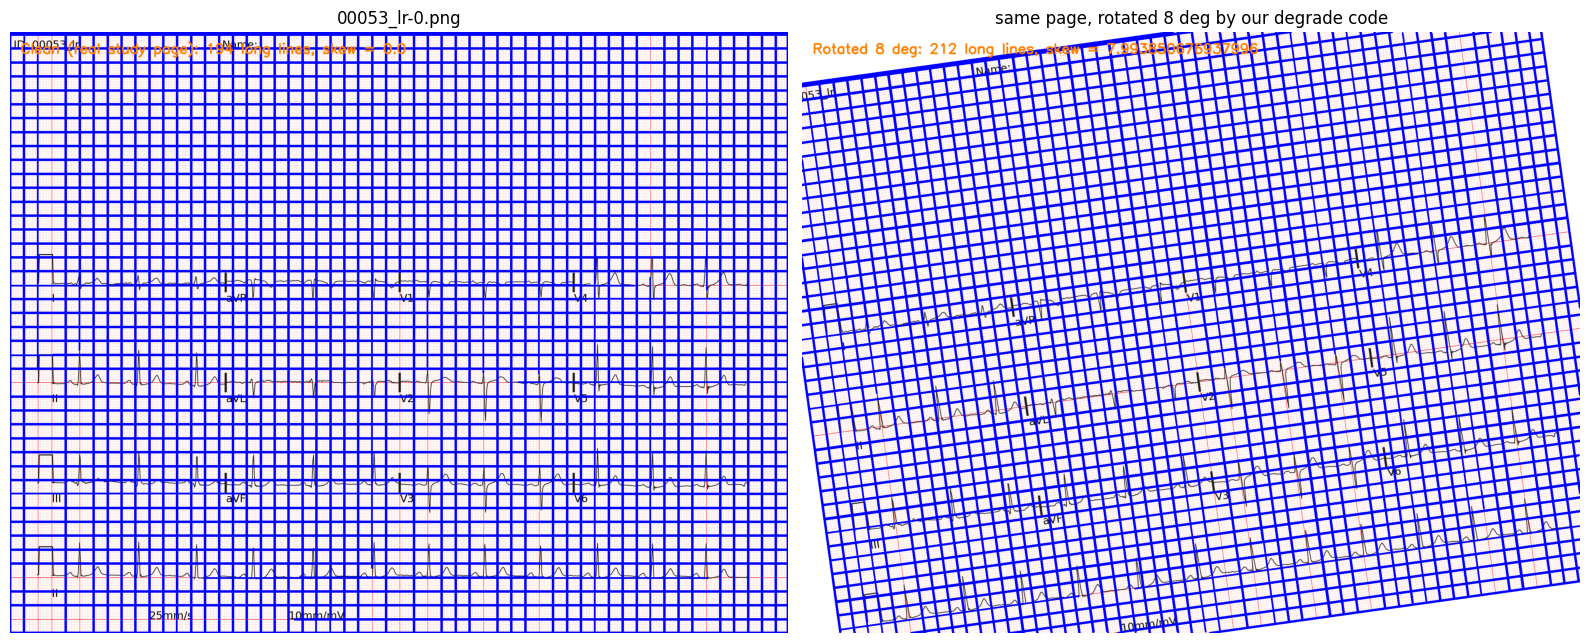

In [4]:
import matplotlib.pyplot as plt

def annotate(im, label):
    out = im.copy()
    g = _gray(im)
    edges = cv2.Canny(g, 50, 150)
    min_len = int(0.3 * g.shape[1])
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=100, minLineLength=min_len, maxLineGap=10)
    n = 0
    if lines is not None:
        lines = lines.reshape(-1, 4) if lines.ndim == 3 else lines
        for x1, y1, x2, y2 in lines:
            cv2.line(out, (x1, y1), (x2, y2), (255, 0, 0), 4)
            n += 1
    measured = skew_deg(im)
    measured_val = measured[0] if measured is not None else None
    cv2.putText(out, f'{label}: {n} long lines, skew = {measured_val}', (30, 60),
                cv2.FONT_HERSHEY_SIMPLEX, 1.3, (0, 128, 255), 3)
    return out

sample_path = clean_files[0]
img_bgr = cv2.imread(sample_path)
rotated = degrade_rotate(img_bgr, 3)  # 8 degrees, matching the sweep's own degradation levels

clean_annot = cv2.cvtColor(annotate(img_bgr, 'Clean (real study page)'), cv2.COLOR_BGR2RGB)
rot_annot = cv2.cvtColor(annotate(rotated, 'Rotated 8 deg'), cv2.COLOR_BGR2RGB)

fig, axs = plt.subplots(1, 2, figsize=(16, 8))
axs[0].imshow(clean_annot); axs[0].axis('off'); axs[0].set_title(os.path.basename(sample_path))
axs[1].imshow(rot_annot); axs[1].axis('off'); axs[1].set_title('same page, rotated 8 deg by our degrade code')
plt.tight_layout(); plt.show()


## Step 5: all five signals, across several real study pages


In [5]:
import pandas as pd

rows = []
for p in clean_files[:10]:
    im = cv2.imread(p)
    if im is None:
        continue
    skew_result = skew_deg(im)
    rows.append({
        'record': os.path.basename(p),
        'blur_score': blur_score(im),
        'skew_deg': skew_result[0] if skew_result is not None else None,
        'resolution_score': resolution_score(im),
        'contrast_score': contrast_score(im),
        'blockiness_score': blockiness_score(im),
    })
df = pd.DataFrame(rows)
df


,record,blur_score,skew_deg,resolution_score,contrast_score,blockiness_score
0,00053_lr-0.png,6562.953109,0.0,0.506915,44.490110,4.449964
1,00102_lr-0.png,6790.455894,0.0,0.511986,46.258863,4.442592
2,00111_lr-0.png,6472.258170,0.0,0.507264,43.469246,4.265889
3,00115_lr-0.png,6648.646785,0.0,0.507690,45.148285,4.073200
4,00120_lr-0.png,6686.106201,0.0,0.503486,45.132851,4.366892
5,00176_lr-0.png,6415.042117,0.0,0.504036,43.213063,4.385732
6,00234_lr-0.png,6636.440934,0.0,0.510390,44.815560,4.371853
7,00369_lr-0.png,6529.950739,0.0,0.507673,44.017281,4.446932
8,00403_lr-0.png,6612.988579,0.0,0.504729,44.819033,3.606789
9,00414_lr-0.png,6655.835570,0.0,0.510402,44.986078,4.390674


## What this confirms, and what is still not done
If the skew values above are all close to 0 (these are undamaged clean pages, so they should be), and the red
lines in Step 4 sit on the page's straight structural lines rather than the ECG trace, the signals are behaving
the same way on real study pages as they did on the 6 local demo images.

**Still not done:** this notebook does not degrade all 1,550 real study variants or fit the signals against
the measured errors in `results_v2.csv`. That calibration -- the actual Phase 2b deliverable -- is the next
step, reusing `scripts/quality_proxy/degrade.py` to regenerate the degraded versions locally from
`images_clean/`, computing all five signals per variant, and joining against `results_v2.csv` by `variant_id`.
